<a href="https://colab.research.google.com/github/ThiagoBrandaorj/cassava-leaf-disease-resnet50/blob/main/AP2_projeto_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Grupo: Thiago Brandão, Fabiano Amorim, Breno França, João Pedro Menezes e Isabella Cristina**

## Classificação de Doenças em Folhas de Mandioca (Cassava Leaf Disease)

Este notebook implementa um pipeline completo de visão computacional para classificar imagens de folhas de mandioca em 5 categorias (4 doenças e folha saudável), utilizando uma rede neural convolucional baseada em *transfer learning* com a arquitetura ResNet50. O trabalho está organizado em três grandes etapas: Análise Exploratória dos Dados (EDA), Pré-processamento e Modelo.

# 1.EDA


### 1.1. Preparação do ambiente e aquisição dos dados

**Configuramos o ambiente e baixamos o dataset da competição do Kaggle. A inspeção da estrutura confirma que temos 21.397 imagens, além dos arquivos `train.csv` e `label_num_to_disease_map.json`.**

In [1]:
# Verifica disponibilidade de GPU
import tensorflow as tf
print("TensorFlow versão:", tf.__version__)
print("GPUs disponíveis:", tf.config.list_physical_devices('GPU'))

TensorFlow versão: 2.21.0
GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**As três células seguintes fazem a autenticação e o download do dataset a partir do Kaggle e inspecionam a estrutura dos arquivos. A saída confirma o acesso bem-sucedido e a presença das 21.397 imagens, além dos arquivos de rótulos.**

In [8]:
# Create the .kaggle directory if it doesn't exist
!mkdir -p ~/.kaggle

# Move the uploaded kaggle.json file to the .kaggle directory
!cp kaggle.json ~/.kaggle/

# Set permissions for the kaggle.json file
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API key configured successfully!")

Kaggle API key configured successfully!


In [9]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('cassava-leaf-disease-classification')

print("Path to competition files:", path)

100%|██████████| 5.76G/5.76G [00:29<00:00, 212MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/cassava-leaf-disease-classification


In [16]:
import os

# Ver estrutura dos arquivos
for item in os.listdir(path):
    full = os.path.join(path, item)
    if os.path.isdir(full):
        n = len(os.listdir(full))
        print(f"📁 {item}/ ({n} arquivos)")
    else:
        size = os.path.getsize(full) / 1e6
        print(f"📄 {item} ({size:.1f} MB)")

📁 test_tfrecords/ (1 arquivos)
📄 train.csv (0.4 MB)
📁 test_images/ (1 arquivos)
📁 train_tfrecords/ (16 arquivos)
📁 train_images/ (21397 arquivos)
📄 label_num_to_disease_map.json (0.0 MB)
📄 sample_submission.csv (0.0 MB)


### 1.2. Carregamento dos rótulos e mapa de classes

**Carregamos os rótulos e o mapa de classes. O dataset contém 21.397 imagens distribuídas em cinco classes: quatro doenças (Cassava Bacterial Blight, Cassava Brown Streak Disease, Cassava Green Mottle e Cassava Mosaic Disease) e a classe Healthy (folha saudável).**

In [13]:
import pandas as pd
import json
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Carregar dados
df = pd.read_csv(f"{path}/train.csv")
with open(f"{path}/label_num_to_disease_map.json") as f:
    label_map = json.load(f)

print("Shape:", df.shape)
print("\nPrimeiras linhas:")
print(df.head())
print("\nMapa de classes:")
for k, v in label_map.items():
    print(f"  {k}: {v}")

Shape: (21397, 2)

Primeiras linhas:
         image_id  label
0  1000015157.jpg      0
1  1000201771.jpg      3
2   100042118.jpg      1
3  1000723321.jpg      1
4  1000812911.jpg      3

Mapa de classes:
  0: Cassava Bacterial Blight (CBB)
  1: Cassava Brown Streak Disease (CBSD)
  2: Cassava Green Mottle (CGM)
  3: Cassava Mosaic Disease (CMD)
  4: Healthy


### 1.3. Distribuição das classes

**O gráfico a seguir revela que o dataset é fortemente desbalanceado. A classe Cassava Mosaic Disease (CMD) representa cerca de 61% das imagens, enquanto Cassava Bacterial Blight (CBB) corresponde a apenas cerca de 5%. Esse desbalanceamento será usado como base para algumas decisões tomadas mais adiantes.**

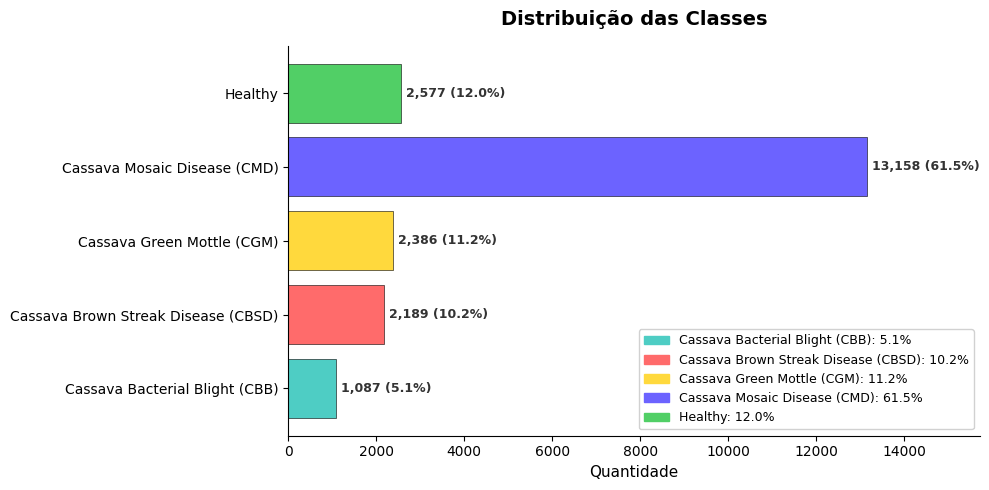

In [14]:
import matplotlib.patches as mpatches

counts = df['label'].value_counts().sort_index()
labels = [label_map[str(i)] for i in counts.index]
values = counts.values
total = values.sum()
colors = ['#4ECDC4', '#FF6B6B', '#FFD93D', '#6C63FF', '#51CF66']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, values, color=colors[:len(labels)], edgecolor='black', linewidth=0.4)

for bar, val in zip(bars, values):
    pct = val / total * 100
    ax.text(
        val + total * 0.005,
        bar.get_y() + bar.get_height() / 2,
        f'{int(val):,} ({pct:.1f}%)',
        va='center', ha='left', fontsize=9, fontweight='bold',
        color='#333333'
    )

legend_patches = [
    mpatches.Patch(color=colors[i], label=f'{labels[i]}: {values[i]/total*100:.1f}%')
    for i in range(len(labels))
]

ax.set_title('Distribuição das Classes', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Quantidade', fontsize=11)
ax.set_xlim(0, max(values) + total * 0.12)
ax.legend(handles=legend_patches, loc='lower right', framealpha=0.9, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### 1.4. Amostras visuais de cada classe

**Ao verificarmos as imagens é revelada a dificuldade do problema: as folhas são fotografadas em campo, com fundos variados, iluminação irregular , diferentes ângulos e várias doenças apresentam sintomas visualmente sutis e parecidos entre si.**

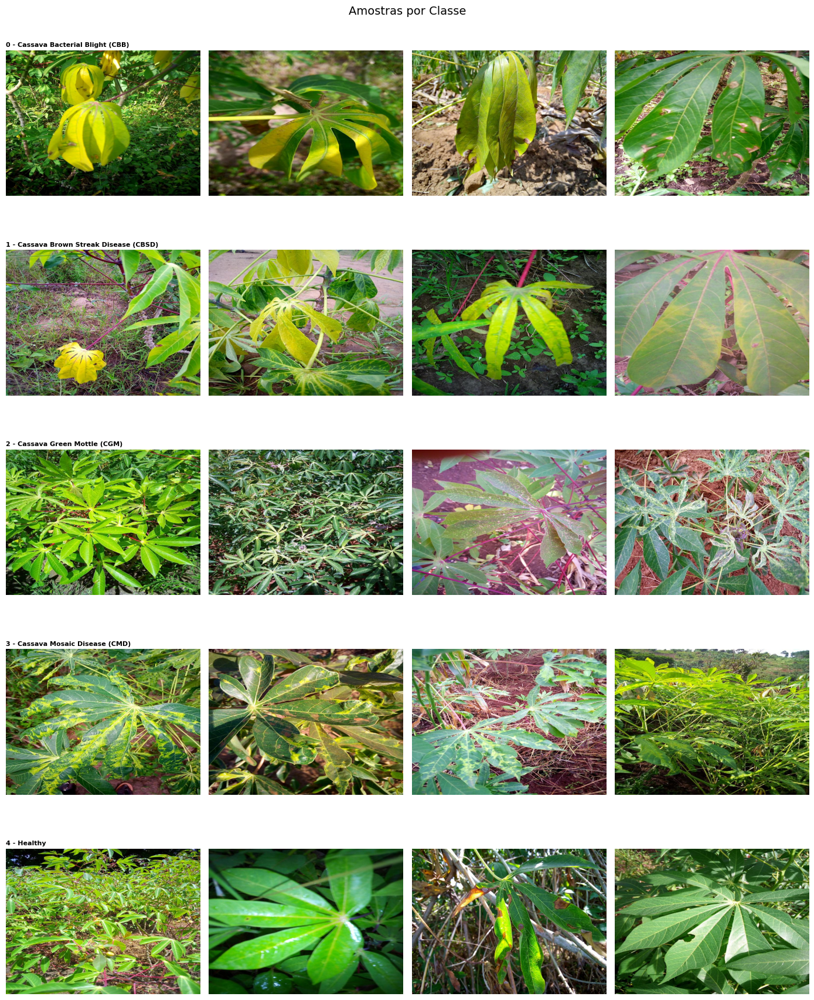

In [17]:
fig, axes = plt.subplots(5, 4, figsize=(14, 18))
img_dir = f"{path}/train_images"

for label_idx in range(5):
    samples = df[df['label'] == label_idx].sample(4, random_state=42)
    for col, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(os.path.join(img_dir, row['image_id']))
        axes[label_idx][col].imshow(img)
        axes[label_idx][col].axis('off')
        if col == 0:
            # Nome curto da classe como título da primeira imagem de cada linha
            nome = label_map[str(label_idx)]
            axes[label_idx][col].set_title(f"{label_idx} - {nome}",
                                            fontsize=8, fontweight='bold',
                                            loc='left', pad=4)

plt.suptitle('Amostras por Classe', fontsize=14)
plt.tight_layout()
plt.show()

### 1.5. Análise das dimensões das imagens

**As estatísticas e histogramas mostram que as imagens possuem o mesmo tamaho: 800 x 600, portanto não temos nenhuma imagem muito pequena ou uma grande variação de tamanhos das imagens.**


📊 ESTATÍSTICAS DAS DIMENSÕES
Total de imagens analisadas: 21397

📏 ALTURA:
   Mediana: 600.0 pixels
   Mínimo:  600 pixels
   Máximo:  600 pixels
   Desvio padrão: 0.0

📐 LARGURA:
   Mediana: 800.0 pixels
   Mínimo:  800 pixels
   Máximo:  800 pixels
   Desvio padrão: 0.0

📊 PROPORÇÃO (Altura/Largura):
   Mediana: 0.75
   Mínimo:  0.75
   Máximo:  0.75


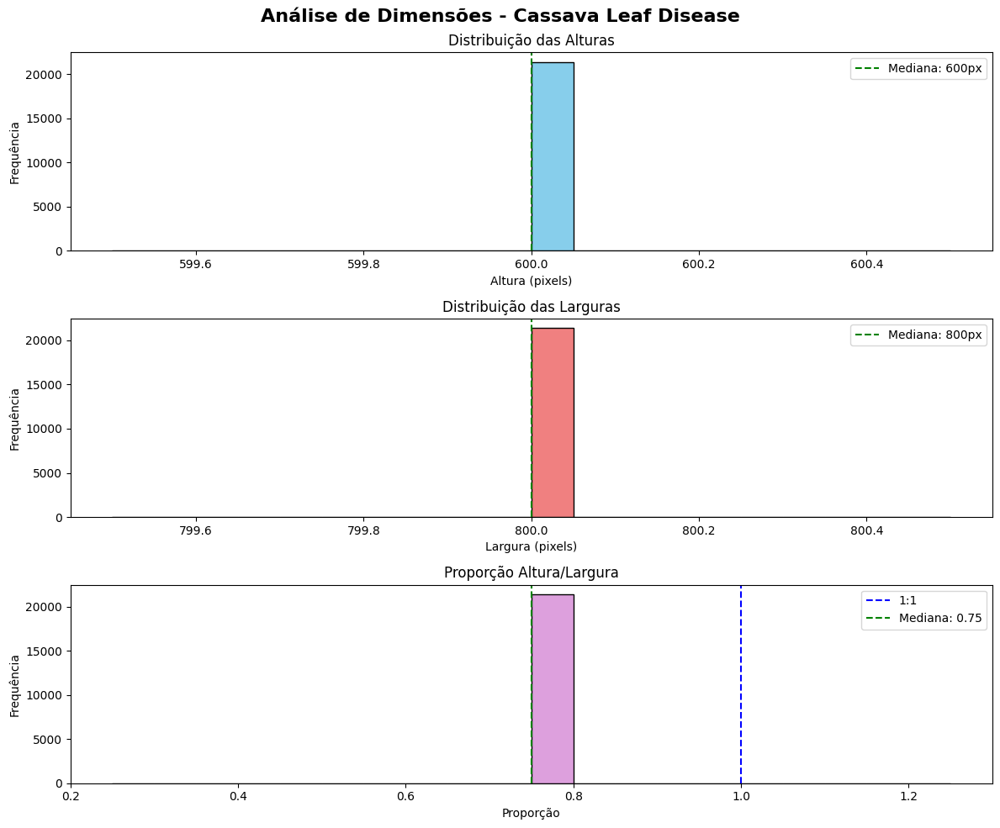

In [18]:
def coletar_dimensoes(img_dir, max_amostras=None):
    alturas = []
    larguras = []
    proporcoes = []

    arquivos = os.listdir(img_dir)
    if max_amostras:
        arquivos = arquivos[:max_amostras]

    for img_name in arquivos:
        img = Image.open(os.path.join(img_dir, img_name))
        w, h = img.size  # PIL retorna (width, height)

        alturas.append(h)
        larguras.append(w)
        proporcoes.append(h / w)

    return {
        'alturas': np.array(alturas),
        'larguras': np.array(larguras),
        'proporcoes': np.array(proporcoes)
    }

img_dir = f"{path}/train_images"
dimensoes = coletar_dimensoes(img_dir)

print("\n" + "="*60)
print("📊 ESTATÍSTICAS DAS DIMENSÕES")
print("="*60)

print(f"Total de imagens analisadas: {len(dimensoes['alturas'])}")

print(f"\n📏 ALTURA:")
print(f"   Mediana: {np.median(dimensoes['alturas']):.1f} pixels")
print(f"   Mínimo:  {np.min(dimensoes['alturas'])} pixels")
print(f"   Máximo:  {np.max(dimensoes['alturas'])} pixels")
print(f"   Desvio padrão: {np.std(dimensoes['alturas']):.1f}")

print(f"\n📐 LARGURA:")
print(f"   Mediana: {np.median(dimensoes['larguras']):.1f} pixels")
print(f"   Mínimo:  {np.min(dimensoes['larguras'])} pixels")
print(f"   Máximo:  {np.max(dimensoes['larguras'])} pixels")
print(f"   Desvio padrão: {np.std(dimensoes['larguras']):.1f}")

print(f"\n📊 PROPORÇÃO (Altura/Largura):")
print(f"   Mediana: {np.median(dimensoes['proporcoes']):.2f}")
print(f"   Mínimo:  {np.min(dimensoes['proporcoes']):.2f}")
print(f"   Máximo:  {np.max(dimensoes['proporcoes']):.2f}")

# Plot
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
fig.suptitle('Análise de Dimensões - Cassava Leaf Disease',
             fontsize=16, fontweight='bold')

# ALTURA
axes[0].hist(dimensoes['alturas'], bins=20, color='skyblue', edgecolor='black')
axes[0].axvline(np.median(dimensoes['alturas']), color='green',
                linestyle='--', label=f"Mediana: {np.median(dimensoes['alturas']):.0f}px")
axes[0].set_title('Distribuição das Alturas')
axes[0].set_xlabel('Altura (pixels)')
axes[0].set_ylabel('Frequência')
axes[0].legend()

# LARGURA
axes[1].hist(dimensoes['larguras'], bins=20, color='lightcoral', edgecolor='black')
axes[1].axvline(np.median(dimensoes['larguras']), color='green',
                linestyle='--', label=f"Mediana: {np.median(dimensoes['larguras']):.0f}px")
axes[1].set_title('Distribuição das Larguras')
axes[1].set_xlabel('Largura (pixels)')
axes[1].set_ylabel('Frequência')
axes[1].legend()

# PROPORÇÃO
axes[2].hist(dimensoes['proporcoes'], bins=20, color='plum', edgecolor='black')
axes[2].axvline(1.0, color='blue', linestyle='--', label='1:1')
axes[2].axvline(np.median(dimensoes['proporcoes']), color='green',
                linestyle='--', label=f"Mediana: {np.median(dimensoes['proporcoes']):.2f}")
axes[2].set_title('Proporção Altura/Largura')
axes[2].set_xlabel('Proporção')
axes[2].set_ylabel('Frequência')
axes[2].legend()

plt.tight_layout()
plt.show()

# 2. Pré-processamento

### 2.1. Divisão estratificada em treino, validação e teste

**Dividimos o conjunto em aproximadamente 70% de treino, 10% de validação e 20% de teste, de forma estratificada, seguindo a referência apresentada[1]. O resultado confirma que a proporção de cada classe foi preservada nos três subconjuntos, o que é essencial em um dataset desbalanceado.**

In [19]:
from sklearn.model_selection import train_test_split

# Total
total = len(df)
train_size = int(0.7 * total)
val_size   = int(0.1 * total)
test_size  = total - train_size - val_size  # garante que não perca nenhuma amostra

print(f"Total: {total}")
print(f"Treino: {train_size}, Validação: {val_size}, Teste: {test_size}")

# Split estratificado (mantém proporção das classes)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

print(f"\nTamanhos após divisão:")
print(f"Treino:    {len(train_df)}")
print(f"Validação: {len(val_df)}")
print(f"Teste:     {len(test_df)}")

print(f"\nDistribuição das classes (%):")
for split_name, split_df in [("Treino", train_df), ("Validação", val_df), ("Teste", test_df)]:
    dist = split_df['label'].value_counts(normalize=True).sort_index()
    dist_str = "  ".join([f"{label_map[str(i)][:]}: {v*100:.1f}%" for i, v in dist.items()])
    print(f"  {split_name}: {dist_str}")

Total: 21397
Treino: 14977, Validação: 2139, Teste: 4281

Tamanhos após divisão:
Treino:    14977
Validação: 3210
Teste:     3210

Distribuição das classes (%):
  Treino: Cassava Bacterial Blight (CBB): 5.1%  Cassava Brown Streak Disease (CBSD): 10.2%  Cassava Green Mottle (CGM): 11.2%  Cassava Mosaic Disease (CMD): 61.5%  Healthy: 12.0%
  Validação: Cassava Bacterial Blight (CBB): 5.1%  Cassava Brown Streak Disease (CBSD): 10.2%  Cassava Green Mottle (CGM): 11.2%  Cassava Mosaic Disease (CMD): 61.5%  Healthy: 12.1%
  Teste: Cassava Bacterial Blight (CBB): 5.1%  Cassava Brown Streak Disease (CBSD): 10.2%  Cassava Green Mottle (CGM): 11.2%  Cassava Mosaic Disease (CMD): 61.5%  Healthy: 12.0%


### 2.2. Verificação da estratificação por conjunto

**Os gráficos confirmam que a divisão estratificada funcionou: as proporções percentuais de cada classe permanecem idênticas nos três subconjuntos.**

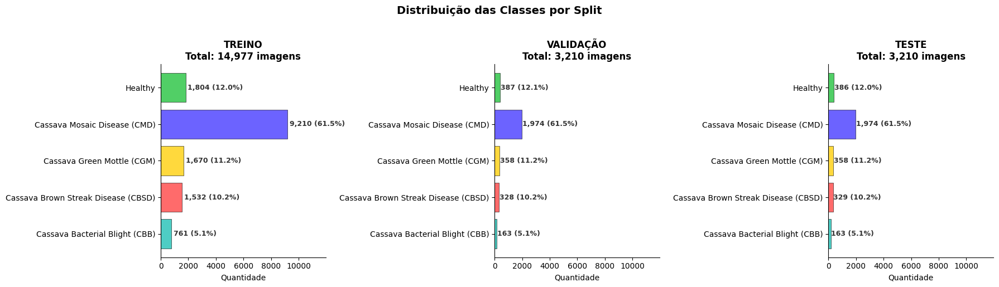

In [20]:
from collections import Counter

classes = list(range(5))
class_names = [label_map[str(i)] for i in classes]
colors = ['#4ECDC4', '#FF6B6B', '#FFD93D', '#6C63FF', '#51CF66']

train_counts = Counter(train_df['label'].tolist())
val_counts   = Counter(val_df['label'].tolist())
test_counts  = Counter(test_df['label'].tolist())

splits = [
    ("TREINO",    [train_counts.get(c, 0) for c in classes]),
    ("VALIDAÇÃO", [val_counts.get(c, 0)   for c in classes]),
    ("TESTE",     [test_counts.get(c, 0)  for c in classes]),
]

global_max = max(max(v) for _, v in splits)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (titulo, values) in zip(axes, splits):
    values = np.array(values)
    total  = values.sum()
    pct    = (values / total) * 100

    bars = ax.barh(class_names, values, color=colors, edgecolor='black', linewidth=0.4)

    for bar, val, p in zip(bars, values, pct):
        ax.text(
            val + total * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{int(val):,} ({p:.1f}%)',
            va='center', ha='left', fontsize=9, fontweight='bold', color='#333333'
        )

    ax.set_title(f'{titulo}\nTotal: {total:,} imagens', fontweight='bold', fontsize=12)
    ax.set_xlabel('Quantidade', fontsize=10)
    ax.set_xlim(0, global_max * 1.3)
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Distribuição das Classes por Split', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 2.3. Pipeline de dados, normalização e data augmentation

**Construímos o pipeline de entrada que lê, redimensiona (336x336), normaliza no padrão esperado pela ResNet e aplica data augmentation (espelhamento, rotação e recorte) apenas no treino. O augmentation dobra o conjunto de treino, de cerca de 15 mil para cerca de 30 mil imagens. A saída confirma o pipeline correto, com batches de shape (128, 336, 336, 3).Além disso dividimos os três subconjuntos(treino,teste e validação) em batchs de tamanho 128. Todas essas etapas foram aplicadas em [1] e com foco em uma performance similar além de diversas tentativas e erros própios definimos esse pipiline.
Além disso, algumas coisas são aplicadas aqui: como o embaralhamento dos dados antes de dividir em batchs, e o PREFETCH, método que carrega o batch seguinte enquanto processa o atual[2].**

In [21]:
tf.keras.backend.clear_session()

IMG_DIR    = f"{path}/train_images"
BATCH_SIZE = 128
IMG_SIZE   = 336

def load_image(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    return img, label

preprocess = tf.keras.Sequential([
    tf.keras.layers.Resizing(height=IMG_SIZE, width=IMG_SIZE, crop_to_aspect_ratio=True),
    tf.keras.layers.Lambda(tf.keras.applications.resnet.preprocess_input)
])

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(mode='horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(factor=(-0.2, 0.2)),
    tf.keras.layers.RandomCrop(height=IMG_SIZE, width=IMG_SIZE)
])

def make_dataset(df, shuffle=False, augment=False):
    paths  = [f"{IMG_DIR}/{fname}" for fname in df['image_id'].tolist()]
    labels = df['label'].tolist()

    resize    = tf.keras.layers.Resizing(IMG_SIZE, IMG_SIZE, crop_to_aspect_ratio=True)
    normalize = tf.keras.layers.Lambda(tf.keras.applications.resnet.preprocess_input)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda X, y: (resize(X), y), num_parallel_calls=tf.data.AUTOTUNE)

    if augment:
        # Dataset original (sem augment)
        ds_original = ds.map(lambda X, y: (normalize(X), y),
                             num_parallel_calls=tf.data.AUTOTUNE)

        # Dataset augmentado
        ds_aug = ds.map(lambda X, y: (data_augmentation(X, training=True), y),
                        num_parallel_calls=tf.data.AUTOTUNE)
        ds_aug = ds_aug.map(lambda X, y: (normalize(X), y),
                            num_parallel_calls=tf.data.AUTOTUNE)

        # Concatenar: dobra o dataset de treino
        ds = ds_original.concatenate(ds_aug)
    else:
        ds = ds.map(lambda X, y: (normalize(X), y),
                    num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(2000, seed=42)  # buffer maior por causa do dobro de imagens

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_set = make_dataset(train_df, shuffle=True, augment=True)
val_set   = make_dataset(val_df, augment=False)
test_set  = make_dataset(test_df, augment=False)

print(f"Batches — Treino: {train_set.cardinality().numpy()}, "
      f"Validação: {val_set.cardinality().numpy()}, "
      f"Teste: {test_set.cardinality().numpy()}")

print(f"\nImagens treino estimadas: {len(train_df) * 2}")

# Verificar shape de um batch
for imgs, labels in train_set.take(1):
    print(f"Shape do batch: {imgs.shape}  dtype: {imgs.dtype}")
    print(f"Labels: {labels.numpy()[:8]}")

Batches — Treino: 235, Validação: 26, Teste: 26

Imagens treino estimadas: 29954
Shape do batch: (128, 336, 336, 3)  dtype: <dtype: 'float32'>
Labels: [3 1 4 1 3 3 3 3]


### 2.4. Inspeção visual do batch após o pré-processamento

**Exibimos algumas imagens já processadas pelo pipeline para confirmar que imagens e rótulos estão corretamente alinhados após todas as etapas.Para conseguirmos visualizar as imagens em formato RGB devemos realizar algumas etapas inversas que a RESNET50 faz ao processar as imagens**

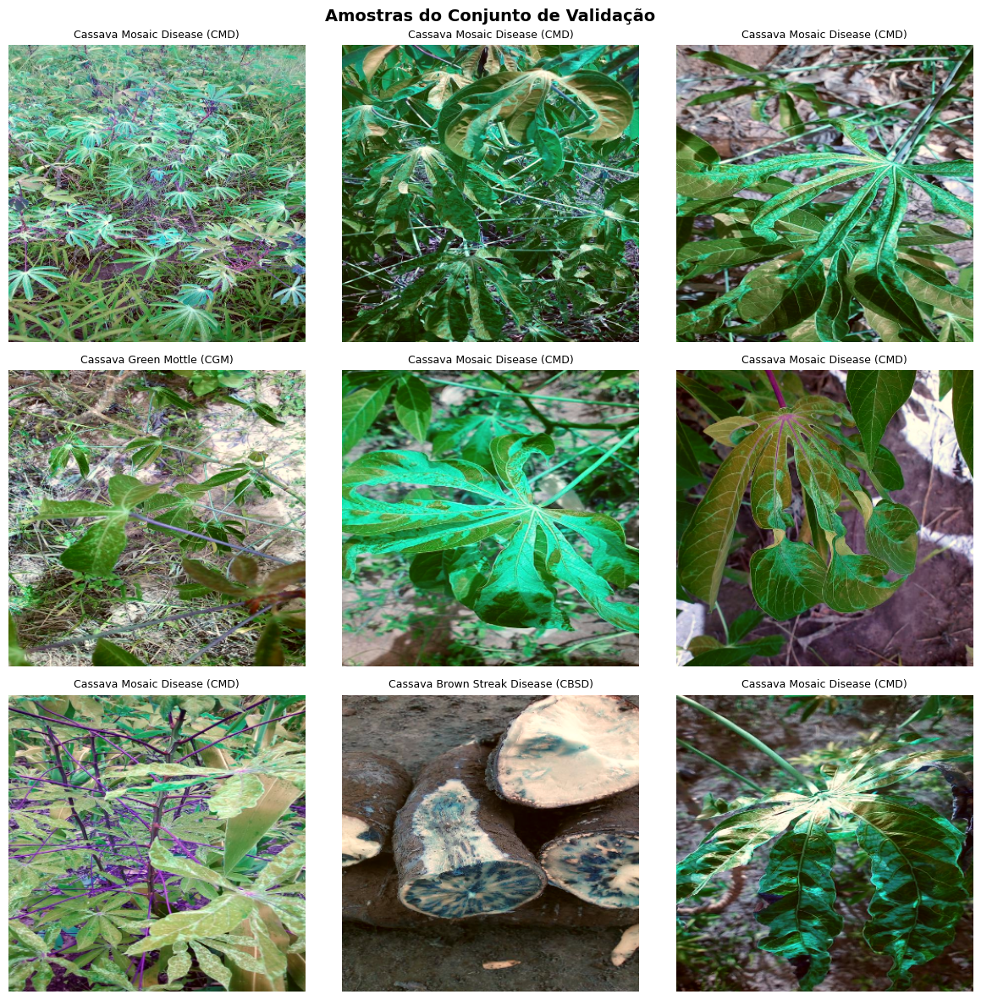

In [22]:
# Médias e desvios do ImageNet (RGB)
IMAGENET_MEAN = np.array([123.68, 116.779, 103.939])

plt.figure(figsize=(12, 12))
for X_batch, y_batch in val_set.take(1):
    for index in range(9):
        plt.subplot(3, 3, index + 1)
        img = X_batch[index].numpy()
        img = img + IMAGENET_MEAN          # reverter subtração da média
        img = np.clip(img / 255.0, 0, 1)  # normalizar para [0, 1]
        plt.imshow(img)
        plt.title(f"{label_map[str(y_batch[index].numpy())]}", fontsize=9)
        plt.axis("off")

plt.suptitle('Amostras do Conjunto de Validação', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Modelo

### 3.1. Arquitetura: ResNet50 pré-treinada e cabeça personalizada

**Usamos a ResNet50 pré-treinada na ImageNet como base, com uma cabeça personalizada para as 5 classes do problema. Na primeira fase, o backbone fica congelado(incluindo o bloco convolucional 5) e apenas a cabeça é treinada. O `model.summary()` confirma a arquitetura e a contagem de parâmetros treináveis e congelados, essa etapa é chamada de FEATURE EXTRACTION.Vale ainda ressaltar que toda a arquitetura da cabeça do modelo foi baseada em [1].**

In [23]:
tf.random.set_seed(42)

n_classes = 5

base_model = tf.keras.applications.ResNet50(weights="imagenet", include_top=False)

# Congelar todas as camadas
for layer in base_model.layers:
    layer.trainable = False

# Verificar
trainable     = sum(1 for l in base_model.layers if l.trainable)
não_trainable = sum(1 for l in base_model.layers if not l.trainable)
print(f"Camadas treináveis:     {trainable}")
print(f"Camadas congeladas:     {não_trainable}")
#print(f"Último bloco descongelado: {[l.name for l in base_model.layers if l.trainable][-1]}")

# Cabeça do modelo
avg    = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
batch_normalization = tf.keras.layers.BatchNormalization()(avg)
dense = tf.keras.layers.Dense(512, activation = "relu",kernel_initializer='he_normal', kernel_regularizer=tf.keras.regularizers.L1L2(l1 = 0.001, l2 = 0.001))(batch_normalization)
drop  = tf.keras.layers.Dropout(0.3)(dense)
batch_normalization_2 = tf.keras.layers.BatchNormalization()(drop)
dense_2 = tf.keras.layers.Dense(256, activation = "relu",kernel_initializer='he_normal', kernel_regularizer=tf.keras.regularizers.L1L2(l1 = 0.001, l2 = 0.001))(batch_normalization_2)
batch_normalization_3 = tf.keras.layers.BatchNormalization()(dense_2)
dense_3 = tf.keras.layers.Dense(32, activation = "relu",kernel_initializer='he_normal', kernel_regularizer=tf.keras.regularizers.L1L2(l1 = 0.001, l2 = 0.001))(batch_normalization_3)
drop_2 = tf.keras.layers.Dropout(0.4)(dense_3)
output = tf.keras.layers.Dense(n_classes, activation="softmax")(drop_2)
model  = tf.keras.Model(inputs=base_model.input, outputs=output)

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Camadas treináveis:     0
Camadas congeladas:     175


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, None,      │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, None,      │      9,472 │ conv1_pad[0][0]   │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, None,      │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, None,      │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, None,      │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, None,      │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, None,      │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, None,      │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, None,      │          0 │ conv2_block1_1_b… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, None,      │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, None,      │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, None,      │          0 │ conv2_block1_2_b… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, None,      │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, None,      │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, None,      │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ None, 256)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, None,      │      1,024 │ conv2_block1_3_c

 Total params: 24,787,781 (94.56 MB)

 Trainable params: 1,194,437 (4.56 MB)

 Non-trainable params: 23,593,344 (90.00 MB)

### 3.2. Cálculo dos pesos de classe

**Calculamos pesos de classe inversamente proporcionais à frequência para lidar com o desbalanceamento. Os valores confirmam essa lógica: a classe CBB (a mais rara) recebe peso próximo de 3,9, enquanto a CMD (a mais comum) recebe peso de cerca de 0,33. Esses pesos fazem com que erros nas classes minoritárias pesem mais no treinamento, uma forma de tentar mitigar o desbalanceamento das classes.**

In [24]:
from sklearn.utils.class_weight import compute_class_weight

labels_train = train_df['label'].values

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels_train),
    y=labels_train
)

class_weights = {
    i: weight for i, weight in zip(np.unique(labels_train), class_weights_array)
}

print("Class weights calculados:")
for k, v in class_weights.items():
    print(f"  Classe {k} ({label_map[str(k)]}): {v:.3f}")

Class weights calculados:
  Classe 0 (Cassava Bacterial Blight (CBB)): 3.936
  Classe 1 (Cassava Brown Streak Disease (CBSD)): 1.955
  Classe 2 (Cassava Green Mottle (CGM)): 1.794
  Classe 3 (Cassava Mosaic Disease (CMD)): 0.325
  Classe 4 (Healthy): 1.660


### 3.3. Callbacks, métrica personalizada e treino da cabeça (Fase 1)

**Definimos os callbacks (ReduceLROnPlateau e EarlyStopping) e uma métrica personalizada de recall médio por classe, mais adequada que a acurácia em um dataset desbalanceado. Em seguida treinamos a cabeça com todo o resto do modelo congelado. Nesta fase, o val_mean_recall sobe de cerca de 0,51 para cerca de 0,66.Aqui, novamente todos os valores dos callbacks foram inspirados em [1].**

In [25]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

lr_first_train = ReduceLROnPlateau(
    monitor='val_mean_recall',
    factor=0.2,
    patience=4,
    min_lr=1e-5,
    cooldown = 2,
    mode = 'max'
)

early_stopping_first_train = EarlyStopping(
    monitor='val_mean_recall',
    mode='max',
    verbose=1,
    restore_best_weights = True,
    patience=5
)

In [26]:
class MeanRecall(tf.keras.metrics.Metric):
    def __init__(self, num_classes=5, name="mean_recall", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.tp = self.add_weight(shape=(num_classes,), initializer="zeros", name="tp")
        self.fn = self.add_weight(shape=(num_classes,), initializer="zeros", name="fn")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_pred_class = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)

        tp_list, fn_list = [], []
        for i in range(self.num_classes):
            label = tf.fill(tf.shape(y_true), i)
            tp_list.append(tf.reduce_sum(tf.cast((y_true == label) & (y_pred_class == label), tf.float32)))
            fn_list.append(tf.reduce_sum(tf.cast((y_true == label) & (y_pred_class != label), tf.float32)))

        self.tp.assign_add(tf.stack(tp_list))
        self.fn.assign_add(tf.stack(fn_list))

    def result(self):
        recall_per_class = self.tp / (self.tp + self.fn + 1e-7)
        return tf.reduce_mean(recall_per_class)

    def reset_state(self):
        self.tp.assign(tf.zeros(self.num_classes))
        self.fn.assign(tf.zeros(self.num_classes))

In [27]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    metrics=[
        MeanRecall(num_classes=5)
    ]
)
history = model.fit(
    train_set,
    validation_data=val_set,
    epochs=10,
    callbacks=[lr_first_train,early_stopping_first_train],
    class_weight=class_weights
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 127s 417ms/step - loss: 36.0742 - mean_recall: 0.3198 - val_loss: 33.8942 - val_mean_recall: 0.5006 - learning_rate: 1.0000e-04
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 76s 316ms/step - loss: 31.9214 - mean_recall: 0.4418 - val_loss: 29.8493 - val_mean_recall: 0.5757 - learning_rate: 1.0000e-04
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 76s 316ms/step - loss: 28.0756 - mean_recall: 0.5139 - val_loss: 26.1782 - val_mean_recall: 0.5956 - learning_rate: 1.0000e-04
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 76s 317ms/step - loss: 24.5375 - mean_recall: 0.5544 - val_loss: 22.7354 - val_mean_recall: 0.6187 - learning_rate: 1.0000e-04
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 76s 316ms/step - loss: 21.2905 - mean_recall: 0.5889 - val_loss: 19.6939 - val_mean_recall: 0.6392 - learning_rate: 1.0000e-04
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 76s 316ms/step - loss: 18.4094 - mean_recall: 0.6080 - val_loss: 16.9999 - val_mean_recall: 0.6440 - learning_rate: 1.0000e-

### 3.4. Curvas de aprendizado da Fase 1

**A perda cai de forma consistente no treino e na validação, e o val_mean_recall cresce de forma estável até cerca de 0,66, sem sinais fortes de overfitting nesta fase. O desempenho ainda está limitado, o que motiva a segunda fase de fine-tuning.**

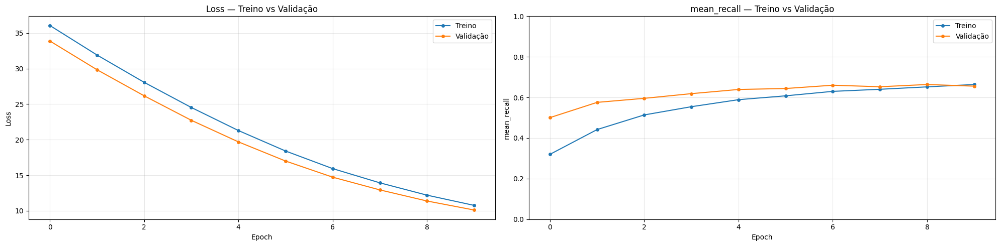

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(20, 5))

# =========================
# 🔹 1. LOSS
# =========================
ax = axes[0]
ax.plot(history.history["loss"], label="Treino", marker='o', markersize=4)
ax.plot(history.history["val_loss"], label="Validação", marker='o', markersize=4)

ax.set_title("Loss — Treino vs Validação")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True, alpha=0.3)


# =========================
# 🔹 2. F1 Macro
# =========================
ax = axes[1]
ax.plot(history.history["mean_recall"], label="Treino", marker='o', markersize=4)
ax.plot(history.history["val_mean_recall"], label="Validação", marker='o', markersize=4)

ax.set_title("mean_recall — Treino vs Validação")
ax.set_xlabel("Epoch")
ax.set_ylabel("mean_recall")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("metricas_completas.png", dpi=150)
plt.show()

### 3.5. Fine-tuning do bloco conv5 (Fase 2)

**Nesta segunda fase descongelamos o último bloco convolucional da ResNet (conv5_block) para especializar as representações para as folhas de mandioca, e treinamos por até 30 épocas. O mean_recall de treino sobe bastante (chegando perto de 0,96), enquanto o val_mean_recall fica em torno de 0,70. A diferença crescente entre treino e validação evidencia algum overfitting nesta fase, e o early stopping restaura os pesos da melhor época. Ainda que um possível overfitting seja questionável, mais a frente veremos que na realidade não estamos diante de um. Novamente aqui os valores foram quase todos inspirados em [1], com apenas uma excessão: na referência em questão o autor usa como métrica de treinamento a acurácia, enquanto que optamos olhar no recall devido ao desbalanceamento das classes, embora esse fator no final não tenha diferenciado tanto assim as métricas comparadas a referêcencia. Vale ainda dizer que no caso dessa referêcencia o autor descongelou TODAS as camadas da RESNET50 nessa fase de FINE TUNNING, diferentemente do nosso caso.**

In [29]:
# Fase 2 — fine-tuning conv5_block
for layer in base_model.layers:
    layer.trainable = "conv5_block" in layer.name
    layer.trainable = "conv4_block" in layer.name

print(f"Camadas treináveis: {sum(1 for l in base_model.layers if l.trainable)}")

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    metrics=[MeanRecall(num_classes=5)]
)

lr_second_train = ReduceLROnPlateau(
    monitor='val_mean_recall',
    factor=0.2,
    patience=4,
    min_lr=1e-5,
    cooldown = 2,
    mode = 'max'
)

early_stopping_second_train = EarlyStopping(
    monitor='val_mean_recall',
    mode='max',
    verbose=1,
    restore_best_weights = True,
    patience=20
)

history_fase2 = model.fit(
    train_set, validation_data=val_set,
    epochs=30,
    class_weight=class_weights,
    callbacks=[lr_second_train, early_stopping_second_train]
)

Camadas treináveis: 62
Epoch 1/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 144s 456ms/step - loss: 10.5969 - mean_recall: 0.6699 - val_loss: 9.5339 - val_mean_recall: 0.7137 - learning_rate: 1.0000e-04
Epoch 2/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 86s 359ms/step - loss: 8.9222 - mean_recall: 0.7409 - val_loss: 8.2580 - val_mean_recall: 0.6864 - learning_rate: 1.0000e-04
Epoch 3/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 86s 359ms/step - loss: 7.5427 - mean_recall: 0.7726 - val_loss: 6.9339 - val_mean_recall: 0.7312 - learning_rate: 1.0000e-04
Epoch 4/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 86s 359ms/step - loss: 6.4104 - mean_recall: 0.8010 - val_loss: 6.0021 - val_mean_recall: 0.7423 - learning_rate: 1.0000e-04
Epoch 5/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 86s 359ms/step - loss: 5.5851 - mean_recall: 0.8137 - val_loss: 5.1733 - val_mean_recall: 0.7444 - learning_rate: 1.0000e-04
Epoch 6/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 86s 359ms/step - loss: 5.0809 - mean_recall: 0.8060 - val_loss: 4.7773 - val_mean_recall: 0.7045 - learning_ra

### 3.6. Curvas de aprendizado da Fase 2

**As curvas evidenciam o comportamento típico do ajuste fino: o desempenho no treino continua subindo de forma acentuada, enquanto a métrica de validação se estabiliza em torno de 0,70. Esse distanciamento entre treino e validação confirma overfitting moderado e explica por que o early stopping restaurou os pesos de uma época intermediária.**

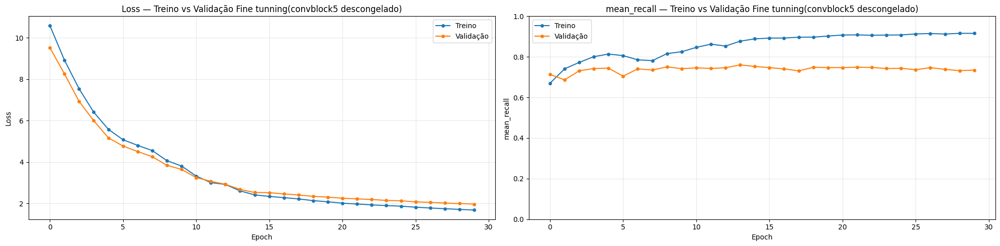

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(20, 5))

# =========================
# 🔹 1. LOSS
# =========================
ax = axes[0]
ax.plot(history_fase2.history["loss"], label="Treino", marker='o', markersize=4)
ax.plot(history_fase2.history["val_loss"], label="Validação", marker='o', markersize=4)

ax.set_title("Loss — Treino vs Validação Fine tunning(convblock5 descongelado)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True, alpha=0.3)


# =========================
# 🔹 2. F1 Macro
# =========================
ax = axes[1]
ax.plot(history_fase2.history["mean_recall"], label="Treino", marker='o', markersize=4)
ax.plot(history_fase2.history["val_mean_recall"], label="Validação", marker='o', markersize=4)

ax.set_title("mean_recall — Treino vs Validação Fine tunning(convblock5 descongelado)")
ax.set_xlabel("Epoch")
ax.set_ylabel("mean_recall")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("metricas_completas_2.png", dpi=150)
plt.show()

### 3.7. Avaliação final no conjunto de teste

**Avaliamos o modelo no conjunto de teste, que não foi usado em nenhuma etapa de treino ou seleção. O mean_recall no teste fica em cerca de 0,70, valor coerente com o observado na validação, o que indica que o modelo não foi superajustado ao conjunto de validação.
O relatório de classificação por classe mostra desempenho alto na classe majoritária CMD (f1 em torno de 0,93) e desempenho mais modesto nas classes raras, refletindo a dificuldade imposta pelo desbalanceamento mesmo com os pesos de classe.
A matriz de confusão concentra a maioria dos acertos na diagonal, mas mostra confusões entre classes com sintomas visualmente parecidos. Isso sugere que coletar mais dados das classes raras ou aplicar augmentations mais específicas poderia melhorar o desempenho.**

In [31]:
model.evaluate(test_set)

26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - loss: 2.6978 - mean_recall: 0.7570


[2.6978278160095215, 0.7570497393608093]


Classification Report:

                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)       0.52      0.65      0.58       163
Cassava Brown Streak Disease (CBSD)       0.71      0.79      0.75       329
         Cassava Green Mottle (CGM)       0.71      0.81      0.75       358
       Cassava Mosaic Disease (CMD)       0.97      0.89      0.93      1974
                            Healthy       0.59      0.66      0.62       386

                           accuracy                           0.83      3210
                          macro avg       0.70      0.76      0.72      3210
                       weighted avg       0.84      0.83      0.83      3210



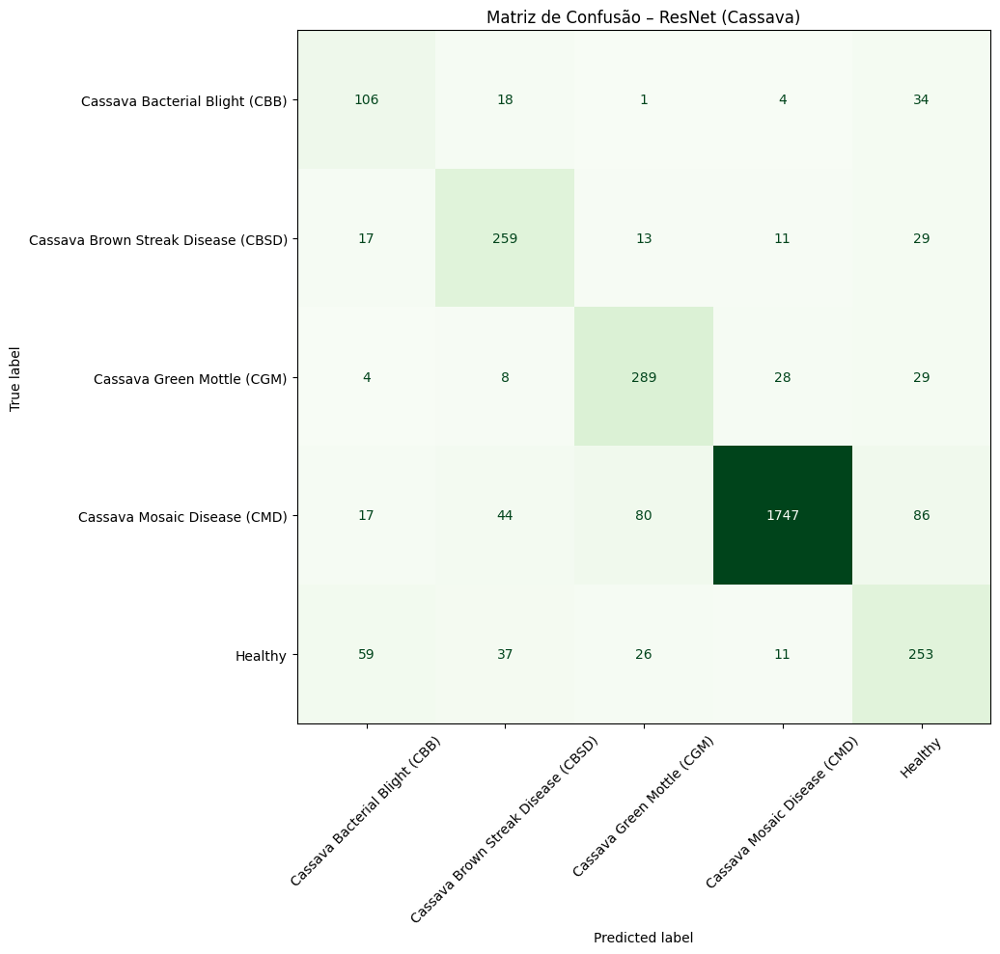

In [32]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = []
y_pred = []

for x_batch, y_batch in test_set:
    preds = model.predict(x_batch, verbose=0)

    y_true.extend(y_batch.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

class_names = [label_map[str(i)] for i in range(5)]

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(20, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Greens", colorbar=False, xticks_rotation=45, ax=ax)

ax.set_title("Matriz de Confusão – ResNet (Cassava)")
plt.tight_layout()
plt.show()
resnet_y_true = y_true
resnet_y_pred = y_pred

# Conclussão Geral

**Podemos concluir ao final que o processo de Transfer Learning da RESNET50 foi banstante útil para melhorar a performance nessa díficil tarefa. No começo do processo de feature extraction o modelo tinha por volta de 50% de recall médio, ao final dessa etapa tinha por volta de 66%, e após o processo de fine tunning chegou a aproximadamente 70% de recall médio e 82% de acurácia. Apesar de ser um problema desbalanceado, comentar sobre a acurácia é bem relevante como forma de comparação, pois o modelo de referência em [1], onde o autor também usou uma RESNET50 a acurácia obtida ao final foi de 86%(cabe ressaltar que o autor na etapa de fine tunning descongelou TODO o modelo), o que exemplifica o quão díficil se trata esse problema. Ainda nesse sentido cabe analisar a referência [3] que nos dá um "teto" de comparação, dizendo que os melhores modelos desenvolvidos nesse problema tendo por volta de 89 - 91% de acurácia(muito deles na verdade são modelos EMSEMBLE, ou seja na prática são compostos por mais de um modelo).**

In [50]:
IMG_SIZE = 336

# Mapa de classes (mesma ordem do treino)
class_names = [
    'Cassava Bacterial Blight (CBB)',   # 0
    'Cassava Brown Streak Disease (CBSD)',  # 1
    'Cassava Green Mottle (CGM)',       # 2
    'Cassava Mosaic Disease (CMD)',     # 3
    'Healthy',                          # 4
]

preprocess = tf.keras.Sequential([
    tf.keras.layers.Resizing(IMG_SIZE, IMG_SIZE, crop_to_aspect_ratio=True),
    tf.keras.layers.Lambda(tf.keras.applications.resnet.preprocess_input)
])

def predict_from_jpg(img_path, model):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.expand_dims(img, axis=0)
    img = preprocess(img)
    return model.predict(img, verbose=0)

# --- Uso ---
pred = predict_from_jpg('folhademandioca.jpg', model)

idx  = int(np.argmax(pred[0]))
nome = class_names[idx]
conf = float(pred[0][idx])

print(f'Shape da predição: {pred.shape}')          # (1, 5)
print(f'Classe prevista:   {nome}')
print(f'Índice:            {idx}')
print(f'Confiança:         {conf:.4f} ({conf*100:.2f}%)')

Shape da predição: (1, 5)
Classe prevista:   Healthy
Índice:            4
Confiança:         0.5627 (56.27%)


In [45]:
img = Image.open('folhademandioca.jpg')

In [46]:
img_array = np.array(img)
img_array.shape

(853, 640, 3)

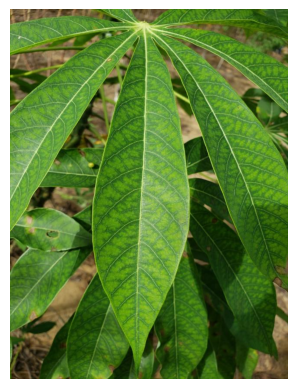

In [47]:
plt.imshow(img)
plt.axis('off')
plt.show()

In [48]:
img = img.resize((IMG_SIZE, IMG_SIZE))
img_array = np.array(img)
img_array.shape

(336, 336, 3)

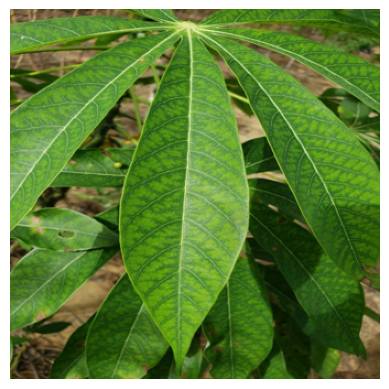

In [49]:
plt.imshow(img_array)
plt.axis('off')
plt.show()

In [51]:
model.save("cassava_model.keras")

# Referências

*   [1].   https://lazylovable.medium.com/cassava-leaf-disease-classification-with-deep-learning-part-iii-3ca80722a209
*   [2]. Géron, Aurélien. Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow. " O'Reilly Media, Inc.", 2022.  
*   [3]. https://chat.deepseek.com/share/csph3ui7lry015oviv